# 10. Kinetic parameter estimation with an ODE model

Fitting rate constants to concentration measurements is the standard example
of a dynamic parameter-estimation problem, and a standard test for global
optimization [tjoa1991simultaneous] [esposito2000global]. The model is the
first-order series reaction $A \xrightarrow{k_1} B \xrightarrow{k_2} C$. With
concentrations scaled by the initial concentration of A, mass-action
kinetics gives the linear ODE system

$$\dot A = -k_1 A, \qquad \dot B = k_1 A - k_2 B, \qquad A(0)=1,\ B(0)=0,$$

with $C = 1 - A - B$, which carries no extra information. Time is in
arbitrary units, the rate constants in inverse time units. We estimate
$k = (k_1, k_2)$ from the concentrations of A and B measured at
$t_n = 1, 2, 3, 4$ by least squares,

$$\min_{k}\ \Phi(k) = \sum_{n=1}^{4} \big(A_n(k) - \hat A_n\big)^2 + \big(B_n(k) - \hat B_n\big)^2
  \qquad \text{s.t.}\quad 0.1 \le k_1 \le 3,\ \ 0.1 \le k_2 \le 3,$$

where $A_n(k), B_n(k)$ are the model's concentrations at $t_n$ and
$\hat A_n, \hat B_n$ the measurements. With equal, independent Gaussian
measurement errors this is the maximum-likelihood estimate.

**Why this is a global problem.** The model is linear in the states but not
in the parameters: $A(t) = e^{-k_1 t}$, and $B(t)$ contains
$k_1/(k_2-k_1)$ times a difference of exponentials. $\Phi$ is a sum of squares
of these nonlinear functions, so it is nonconvex in $k$, and nothing rules out
several local minima. A local least-squares solver (Gauss-Newton,
Levenberg-Marquardt, L-BFGS) converges to the minimum whose basin it starts
in and cannot tell whether a better one exists. Below we find that the
discretized model used here has two local minima, and that one start in
several from a uniform random point ends in the wrong one.

**The data are synthetic.** They are generated below from the analytic solution with true values $k_1 = 1.0$, $k_2 = 0.5$ plus Gaussian noise
(standard deviation 0.01, `numpy` seed 0). Nothing here is experimental data.

**Both models use the same discretization.** To make the optimum identical, both use one classical fixed-step RK4 step per measurement interval
($h = 1$, four steps). The step function `rk4_step` is plain Python arithmetic, so the *same* function can be called on JAX numbers and on Pyomo variables.
The difference is what surrounds it: in jaxglobal the states are local Python variables inside the objective, while in Pyomo every state at every step
is a `Var`, linked to the previous one by a `Constraint`. (Step size 1 is coarse for $k$ near 3, but it is the same discrete model on both sides.
The reason for so few steps is a limit of jaxglobal, discussed at the end.)

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pyomo.environ as pyo
from scipy.optimize import minimize as sp_minimize

from nbutil import loc, model_size, save_results, solve_jax, solve_pyomo, table

INK, MUTED, BLUE, ORANGE, AQUA, YELLOW = "#1a1a19", "#77766f", "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": MUTED,
                     "axes.grid": True, "grid.color": "#e6e5df", "grid.linewidth": 0.6, "figure.dpi": 110})
COLOR = {"scip": BLUE, "couenne": AQUA, "baron": YELLOW, "jaxglobal": ORANGE}  # one color per solver, in every figure

K1_TRUE, K2_TRUE, SIGMA = 1.0, 0.5, 0.01
N, H = 4, 1.0
T_OBS = H * np.arange(1, N + 1)
rng = np.random.default_rng(0)
Y_A = np.exp(-K1_TRUE * T_OBS) + SIGMA * rng.standard_normal(N)
Y_B = K1_TRUE / (K2_TRUE - K1_TRUE) * (np.exp(-K1_TRUE * T_OBS) - np.exp(-K2_TRUE * T_OBS)) + SIGMA * rng.standard_normal(N)
print("synthetic data (A, B):")
print(np.round(np.c_[T_OBS, Y_A, Y_B], 4))

synthetic data (A, B):
[[1.     0.3691 0.4719]
 [2.     0.134  0.4687]
 [3.     0.0562 0.3597]
 [4.     0.0194 0.2435]]


## The discretization: one RK4 step per measurement interval

For $\dot y = f(y)$ with $y = (A, B)$, the classical fourth-order Runge-Kutta
step of length $h$ is

$$\kappa_1 = f(y_n),\quad \kappa_2 = f\!\big(y_n + \tfrac h2 \kappa_1\big),\quad
  \kappa_3 = f\!\big(y_n + \tfrac h2 \kappa_2\big),\quad \kappa_4 = f(y_n + h\kappa_3),$$

$$y_{n+1} = y_n + \tfrac h6\,(\kappa_1 + 2\kappa_2 + 2\kappa_3 + \kappa_4).$$

`rk4_step` below is exactly this, with
$f(A,B) = (-k_1 A,\ k_1 A - k_2 B)$. Because the ODE is linear,
$f(y) = My$ with $M = \begin{pmatrix} -k_1 & 0 \\ k_1 & -k_2 \end{pmatrix}$, the
step collapses to a matrix polynomial,

$$y_{n+1} = R(hM)\,y_n, \qquad R(z) = 1 + z + \tfrac{z^2}{2} + \tfrac{z^3}{6} + \tfrac{z^4}{24},$$

the degree-4 Taylor polynomial of $e^z$. For species A this gives the closed
form $A_n = R(-k_1 h)^n$: after four steps the model value is a polynomial of
degree 16 in $k_1$, and its square in $\Phi$ of degree 32. The Pyomo model
states the same thing as eight polynomial equality constraints, one per
state per step.

In [2]:
def rk4_step(A, B, k1, k2, h=H):
    """One RK4 step for the series reaction; works on floats, JAX values or Pyomo expressions."""

    def rhs(a, b):
        return -k1 * a, k1 * a - k2 * b

    a1, b1 = rhs(A, B)
    a2, b2 = rhs(A + h / 2 * a1, B + h / 2 * b1)
    a3, b3 = rhs(A + h / 2 * a2, B + h / 2 * b2)
    a4, b4 = rhs(A + h * a3, B + h * b3)
    return A + h / 6 * (a1 + 2 * a2 + 2 * a3 + a4), B + h / 6 * (b1 + 2 * b2 + 2 * b3 + b4)

## jaxglobal model

Two decision variables. The ODE solution is computed inside the objective by a Python loop.

In [3]:
def sse(k):
    A, B, err = 1.0, 0.0, 0.0
    for n in range(N):
        A, B = rk4_step(A, B, k[0], k[1])
        err = err + (A - Y_A[n]) ** 2 + (B - Y_B[n]) ** 2
    return err

## The landscape, and why a local solver is not enough

Two parameters means $\Phi$ can simply be drawn. `sse` is plain arithmetic, so
it evaluates on a whole grid of numpy arrays at once. For comparison, the
same objective with the exact (analytic) solution of the ODE,

$$A(t) = e^{-k_1 t}, \qquad B(t) = \frac{k_1}{k_2 - k_1}\left(e^{-k_1 t} - e^{-k_2 t}\right),$$

is drawn next to it. Local minima of each grid are marked, and 100 L-BFGS-B
runs from uniform random starts in the box show where a local solver ends up.

In [4]:
def exact(k1, k2, t):
    """Analytic solution of the series reaction (k1 == k2 is a removable singularity, nudged away)."""
    d = np.where(np.abs(k2 - k1) < 1e-8, 1e-8, k2 - k1)
    return np.exp(-k1 * t), k1 / d * (np.exp(-k1 * t) - np.exp(-(k1 + d) * t))


def sse_exact(k):
    err = 0.0
    for n in range(N):
        A, B = exact(k[0], k[1], T_OBS[n])
        err = err + (A - Y_A[n]) ** 2 + (B - Y_B[n]) ** 2
    return err


def grid_minima(S, g, size=5):
    """Grid points that are the smallest value in their size x size neighbourhood (interior candidates)."""
    from scipy.ndimage import minimum_filter

    idx = np.argwhere(S == minimum_filter(S, size=size, mode="nearest"))
    return [(g[i], g[j], S[i, j]) for i, j in idx]


g = np.linspace(0.1, 3, 291)
K1, K2 = np.meshgrid(g, g, indexing="ij")
S_rk4 = sse((K1, K2))
S_ex = sse_exact((K1, K2))

starts = np.random.default_rng(1).uniform(0.1, 3, (100, 2))
local_ends = {}
for name, f in (("RK4", sse), ("exact", sse_exact)):
    runs = [sp_minimize(f, s, method="L-BFGS-B", bounds=[(0.1, 3)] * 2) for s in starts]
    ends = np.array([r.x for r in runs])
    local_ends[name] = ends
    pts, inv, counts = np.unique(ends.round(2), axis=0, return_inverse=True, return_counts=True)
    print(f"{name:5s} model, L-BFGS-B from 100 random starts, end points (rounded) and counts:")
    for i, (p, c) in enumerate(zip(pts, counts)):
        mine = [r for r, j in zip(runs, inv.ravel()) if j == i]
        print(f"      k = ({p[0]:.2f}, {p[1]:.2f})  x{c:3d}   Phi = {min(r.fun for r in mine):.3e}"
              f"   max |gradient| = {max(np.abs(r.jac).max() for r in mine):.1e}")
for name, S in (("RK4", S_rk4), ("exact", S_ex)):
    print(f"{name:5s} grid local minima:", [f"({a:.2f}, {b:.2f}): {v:.2e}" for a, b, v in grid_minima(S, g)])

RK4   model, L-BFGS-B from 100 random starts, end points (rounded) and counts:
      k = (1.01, 0.48)  x 83   Phi = 5.717e-05   max |gradient| = 1.1e-05
      k = (2.01, 0.36)  x 17   Phi = 3.982e-03   max |gradient| = 1.3e-05


exact model, L-BFGS-B from 100 random starts, end points (rounded) and counts:
      k = (0.65, 1.55)  x  1   Phi = 3.114e-01   max |gradient| = 4.8e-01
      k = (0.66, 1.20)  x  1   Phi = 2.336e-01   max |gradient| = 4.7e-01
      k = (0.66, 1.31)  x  1   Phi = 2.618e-01   max |gradient| = 4.8e-01
      k = (0.99, 0.49)  x 97   Phi = 1.057e-04   max |gradient| = 9.0e-06
RK4   grid local minima: ['(1.01, 0.48): 8.30e-05', '(2.02, 0.36): 3.99e-03']
exact grid local minima: ['(0.99, 0.49): 1.18e-04']


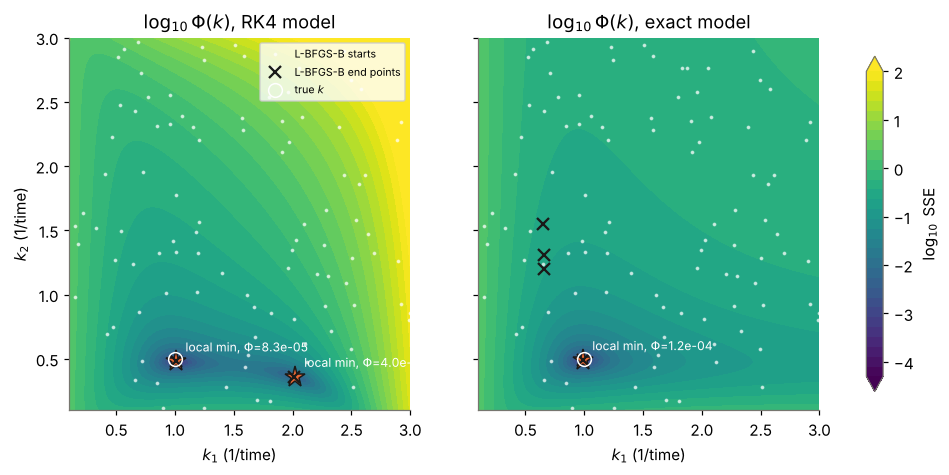

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), sharey=True)
levels = np.linspace(-4.3, 2.0, 32)
for ax, S, name in ((axes[0], S_rk4, "RK4"), (axes[1], S_ex, "exact")):
    cs = ax.contourf(g, g, np.log10(S).T, levels=levels, cmap="viridis", extend="both")
    ends = local_ends[name]
    ax.plot(*starts.T, ".", color="white", ms=3, alpha=0.6, label="L-BFGS-B starts")
    for (a, b, v) in grid_minima(S, g):
        ax.plot(a, b, "*", color=ORANGE, ms=14, mec=INK)
        ax.annotate(f"local min, $\\Phi$={v:.1e}", (a, b), xytext=(6, 6), textcoords="offset points", color="white", fontsize=8)
    ax.plot(*np.unique(ends.round(2), axis=0).T, "x", color=INK, ms=8, mew=1.5, label="L-BFGS-B end points")
    ax.plot(K1_TRUE, K2_TRUE, "o", mfc="none", mec="white", ms=9, label="true $k$")
    ax.set_title(f"$\\log_{{10}}\\Phi(k)$, {name} model")
    ax.grid(False)
    ax.set_xlabel("$k_1$ (1/time)")
axes[0].set_ylabel("$k_2$ (1/time)")
axes[0].legend(loc="upper right", fontsize=7, framealpha=0.8)
fig.colorbar(cs, ax=axes, shrink=0.9, label="$\\log_{10}$ SSE", ticks=np.arange(-4, 3))
plt.show()

**How to read this.** Both landscapes are long, curved valleys: $k_1$ is
pinned by the decay of A, while $k_2$ trades off against $k_1$ along the
valley floor. The RK4 landscape (left) has a second local minimum near
$k_1 \approx 2$, and the printed counts show the fraction of random starts that
L-BFGS-B delivers there. The exact model (right) has no basin there.

The second minimum is an artifact of the discretization, and the closed form
above explains it. A decays by the factor $R(-k_1 h)$ per step, and $R(-z)$ is
not monotone: it falls to a minimum near $z \approx 1.6$ and rises again
(the next figure). A per-step factor near the measured
$\hat A_1 \approx 0.37$ is produced by two values of $k_1$, one near 1 and one
near 2, while $e^{-k_1}$ produces it only once. A local solver started in the
wrong basin returns a fit that is worse than the global one and gives no sign
of it; a global solver either proves the minimum or reports a gap.

The exact-model runs do not all agree either: a few stop far from any
minimum, with a gradient that is clearly not zero (printed above). There
L-BFGS-B's line search made no progress on the curved valley wall and the
run ended on its "relative reduction of F" test. These are not local minima,
but a local solver reports them as converged all the same, which is the
other way local solvers fail on such landscapes.

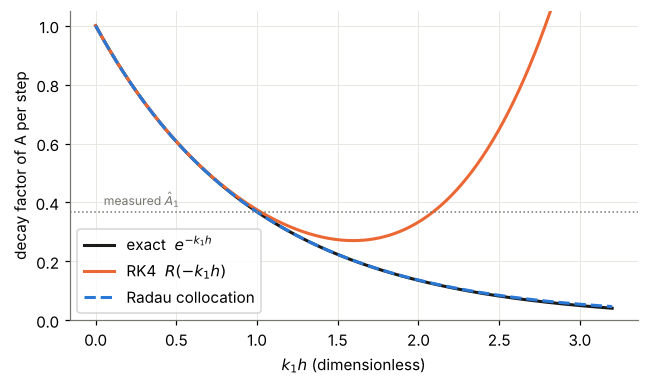

RK4 decay factor has its minimum 0.270 at k1*h = 1.60; exact e^-k1h is monotone


In [6]:
z = np.linspace(0, 3.2, 300)
R_rk4 = 1 - z + z**2 / 2 - z**3 / 6 + z**4 / 24
R_radau = (1 - 2 * z / 5 + z**2 / 20) / (1 + 3 * z / 5 + 3 * z**2 / 20 + z**3 / 60)  # 3-stage Radau IIA, see below
fig, ax = plt.subplots(figsize=(6, 3.6))
ax.plot(z, np.exp(-z), color=INK, lw=2, label="exact  $e^{-k_1 h}$")
ax.plot(z, R_rk4, color=ORANGE, lw=2, label="RK4  $R(-k_1 h)$")
ax.plot(z, R_radau, color=BLUE, lw=2, ls="--", label="Radau collocation")
ax.axhline(Y_A[0], color=MUTED, lw=1, ls=":")
ax.annotate("measured $\\hat A_1$", (0.05, Y_A[0] + 0.02), color=MUTED, fontsize=8)
ax.set_xlabel("$k_1 h$ (dimensionless)")
ax.set_ylabel("decay factor of A per step")
ax.set_ylim(0, 1.05)
ax.legend()
plt.tight_layout()
plt.show()
zz = np.linspace(0, 3, 30001)
Rz = 1 - zz + zz**2 / 2 - zz**3 / 6 + zz**4 / 24
print(f"RK4 decay factor has its minimum {Rz.min():.3f} at k1*h = {zz[Rz.argmin()]:.2f}; exact e^-k1h is monotone")

## Pyomo model: explicit RK4 as algebraic equations

One `Var` per state per time step, one equality constraint per state per step, and the objective summed over the measurements.
This is the *full-space* or simultaneous formulation [tjoa1991simultaneous]:

$$\min_{k,\,A_{1..4},\,B_{1..4}} \ \sum_{n=1}^4 (A_n - \hat A_n)^2 + (B_n - \hat B_n)^2
  \quad\text{s.t.}\quad (A_{n+1}, B_{n+1}) = \mathrm{RK4}(A_n, B_n; k),\ \ n = 0,\dots,3,$$

with $A_0 = 1$, $B_0 = 0$ fixed and the states bounded by $[0, 1]$. The
global solvers relax each nonlinear term of the constraints separately and
branch on $k$ and on the states.

In [7]:
def rk4_pyomo():
    m = pyo.ConcreteModel()
    m.k1 = pyo.Var(bounds=(0.1, 3), initialize=1.0)
    m.k2 = pyo.Var(bounds=(0.1, 3), initialize=1.0)
    m.n = pyo.RangeSet(0, N)
    m.A = pyo.Var(m.n, bounds=(0, 1), initialize=0.5)
    m.B = pyo.Var(m.n, bounds=(0, 1), initialize=0.2)
    m.A[0].fix(1.0)
    m.B[0].fix(0.0)
    m.steps = pyo.ConstraintList()
    for n in range(N):
        An, Bn = rk4_step(m.A[n], m.B[n], m.k1, m.k2)
        m.steps.add(m.A[n + 1] == An)
        m.steps.add(m.B[n + 1] == Bn)
    m.obj = pyo.Objective(expr=sum((m.A[n + 1] - Y_A[n]) ** 2 + (m.B[n + 1] - Y_B[n]) ** 2 for n in range(N)))
    return m

Solving. jaxglobal needs reduced options here: with the defaults (OBBT, univariate envelopes, alphaBB, FBBT) the first JIT compilation of the
unrolled RK4 graph took minutes already for three steps on this machine, so we turn those features off and use plain McCormick relaxations with interval arithmetic.
That is a real cost of this style of model in the current prototype (see the end).

jaxglobal works in *reduced space*: it branches only on $k_1, k_2$ and
propagates McCormick relaxations [mccormick1976computability] through the
four unrolled RK4 steps, the relaxation of an algorithm in the sense of
[mitsos2009mccormick]. The Pyomo solvers (SCIP [vigerske2018scip], Couenne
[belotti2009branching], BARON when installed) see the full-space model above.
`solve_jax` keeps only a summary of jaxglobal's `Result`; the small wrapper
below also keeps the full `Result`, whose `history` is plotted further down.
It does not change the solve.

In [8]:
import jaxglobal

_minimize, _last = jaxglobal.minimize, {}


def _keep_result(*args, **kw):
    _last["result"] = r = _minimize(*args, **kw)
    return r


JAX_OPTS = dict(univariate=False, alphabb=False, fbbt=False, dbbt=False, obbt=False)
m = rk4_pyomo()
size = model_size(m)
print(f"Pyomo explicit RK4: {size[0]} free variables, {size[1]} constraints (two more fixed initial conditions)")
rows = [solve_pyomo(rk4_pyomo(), s) for s in ("scip", "couenne", "baron")]
jaxglobal.minimize = _keep_result  # solve_jax imports jaxglobal.minimize when called
try:
    rows.append(solve_jax(sse, [0.1, 0.1], [3.0, 3.0], **JAX_OPTS))
finally:
    jaxglobal.minimize = _minimize
res_jax = _last["result"]
table(rows)

Pyomo explicit RK4: 10 free variables, 8 constraints (two more fixed initial conditions)


,solver,obj,bound,time,status
0,scip,0.000057,0.000056,0.59,optimal
1,couenne,0.000057,NaN,0.33,optimal
2,baron,NaN,NaN,NaN,not run: GAMS/BARON not installed
3,jaxglobal,0.000057,0.000057,4.95,optimal


**Reading the table.** `obj` is the best SSE found, `bound` the proven lower
bound (Couenne does not report one through the `.nl` interface, hence `NaN`). All solvers
get the same relative gap $10^{-4}$ and absolute gap $10^{-6}$ (see
`nbutil.py`), and they stop at whichever is reached first. Here the optimal SSE is
itself only a few times $10^{-5}$, so the absolute gap is the one that
triggers: a few percent of the objective. That is why a solver can report
"optimal" with an objective slightly above another's; the printout below gives
the relative gaps.

In [9]:
print("solver      obj           bound         (obj-bound)/obj")
for r in rows:
    if not np.isfinite(r["obj"]):
        print(f"{r['solver']:10s}  {r['status']}")
        continue
    rel = f"{(r['obj'] - r['bound']) / r['obj']:.2%}" if np.isfinite(r["bound"]) else "no bound reported"
    print(f"{r['solver']:10s}  {r['obj']:.6e}  {r['bound']:.6e}  {rel}")
print(f"jaxglobal: {rows[-1]['nodes']} nodes, {res_jax.iterations} iterations")

solver      obj           bound         (obj-bound)/obj
scip        5.717219e-05  5.622154e-05  1.66%
couenne     5.716690e-05  nan  no bound reported
baron       not run: GAMS/BARON not installed
jaxglobal   5.716690e-05  5.656386e-05  1.05%
jaxglobal: 141 nodes, 24 iterations


The parameter values come from the solved Pyomo model. BARON is the reference
when it is installed; otherwise the Pyomo solver with the lowest objective is
used.

In [10]:
pyomo_rows = [r for r in rows if r["solver"] != "jaxglobal" and np.isfinite(r["obj"])]
REF = "baron" if any(r["solver"] == "baron" for r in pyomo_rows) else min(pyomo_rows, key=lambda r: r["obj"])["solver"]
mm = rk4_pyomo()
solve_pyomo(mm, REF)
k_rk4_pyomo = np.array([pyo.value(mm.k1), pyo.value(mm.k2)])
k_rk4 = np.asarray(rows[-1]["x"], float)
print(f"Pyomo ({REF}) k1, k2 = {k_rk4_pyomo[0]:.4f}, {k_rk4_pyomo[1]:.4f}")
print(f"jaxglobal     k1, k2 = {k_rk4[0]:.4f}, {k_rk4[1]:.4f}   (true values {K1_TRUE}, {K2_TRUE}; the data are noisy)")
print(f"jaxglobal objective at the Pyomo ({REF}) optimum: {float(sse(k_rk4_pyomo)):.6e}")

Pyomo (couenne) k1, k2 = 1.0146, 0.4760
jaxglobal     k1, k2 = 1.0146, 0.4760   (true values 1.0, 0.5; the data are noisy)
jaxglobal objective at the Pyomo (couenne) optimum: 5.716690e-05


### How jaxglobal's bounds close

`Result.history` holds one row per branch-and-bound iteration: iteration,
nodes created so far, global lower bound $L$, incumbent $U$ and open boxes.
The incumbent comes from the local solve at the root, so $U$ is flat; the work
is in raising $L$. The lower bound starts at 0 (the SSE is nonnegative and the
root relaxation is weaker than that), so the gap is shown relative to $U$.

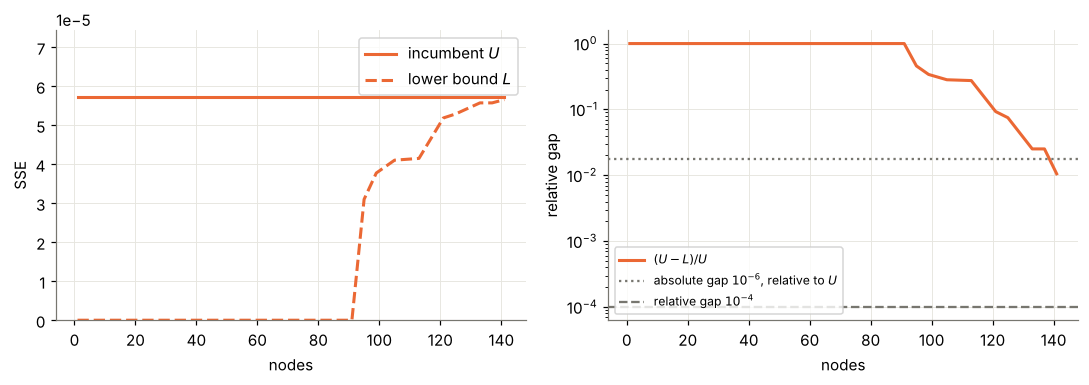

In [11]:
hist = np.array(res_jax.history, float)  # (iteration, nodes, L, U, open boxes)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
ax = axes[0]
ax.plot(hist[:, 1], hist[:, 3], color=ORANGE, lw=2, label="incumbent $U$")
ax.plot(hist[:, 1], hist[:, 2], color=ORANGE, lw=2, ls="--", label="lower bound $L$")
ax.set_ylim(0, 1.3 * hist[-1, 3])
ax.set_xlabel("nodes")
ax.set_ylabel("SSE")
ax.legend()
ax = axes[1]
ax.semilogy(hist[:, 1], (hist[:, 3] - hist[:, 2]) / hist[:, 3], color=ORANGE, lw=2, label="$(U-L)/U$")
ax.axhline(1e-6 / hist[-1, 3], color=MUTED, ls=":", label="absolute gap $10^{-6}$, relative to $U$")
ax.axhline(1e-4, color=MUTED, ls="--", label="relative gap $10^{-4}$")
ax.set_xlabel("nodes")
ax.set_ylabel("relative gap")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

For a long stretch of the search the lower bound is no better than the
trivial bound 0: the relaxations over the larger boxes are too weak to say
anything. Once the boxes around the minimum are small enough the bound rises
in steps, and the search stops when the gap crosses the absolute-gap line,
well before the relative-gap line. The many nodes for two variables are the price of weak
relaxations: the bounds on the states after step $n$ are computed from the
bounds after step $n-1$, and the overestimation compounds over the four steps.

In [12]:
lp, lj = loc(rk4_pyomo, rk4_step), loc(sse, rk4_step)
save_results("10", "RK4 kinetics (explicit)", lp, lj, size, rows, note="same RK4 discretization")
print(f"lines of model code (including the shared rk4_step): Pyomo {lp}, jaxglobal {lj}")

lines of model code (including the shared rk4_step): Pyomo 24, jaxglobal 14


## Pyomo model: `pyomo.dae`

The idiomatic Pyomo way is not to write the integrator but to declare the ODE with a `ContinuousSet` and `DerivativeVar`
and let a transformation discretize it [bynum2021pyomo]. Here: orthogonal collocation on finite elements (3-point Radau, one element per measurement interval).

On each element $[t_n, t_n + h]$ the states are polynomials of degree 3, fixed
by the value at $t_n$ and the values at the collocation points
$t_n + c_j h$ with $c = \big(\tfrac{4-\sqrt6}{10}, \tfrac{4+\sqrt6}{10}, 1\big)$.
The ODE is imposed only at those three points,

$$\frac{d}{dt}\,y(t_n + c_j h) = f\big(y(t_n + c_j h)\big), \qquad j = 1,2,3,$$

and the last point is the next element's start, so the states are continuous.
Every state value and every derivative at every collocation point is a
variable; the transformation writes the polynomial relation between them
(the collocation equations) as linear constraints. The scheme is the
implicit Runge-Kutta method Radau IIA, of order 5. For our linear ODE it
again reduces to $y_{n+1} = R(hM)\,y_n$, now with the rational function

$$R_{\text{Radau}}(z) = \frac{1 + \tfrac25 z + \tfrac1{20} z^2}{1 - \tfrac35 z + \tfrac3{20} z^2 - \tfrac1{60} z^3},$$

a Padé approximant of $e^z$ that decreases monotonically for $z < 0$ (the blue
curve in the figure above). It is a different discretization than the RK4
above, so the optimum differs; it is closer to the exact solution, and it
has no spurious second minimum.

In [13]:
from pyomo.dae import ContinuousSet, DerivativeVar


def dae_pyomo():
    m = pyo.ConcreteModel()
    m.t = ContinuousSet(initialize=[0.0, *T_OBS])
    m.k1 = pyo.Var(bounds=(0.1, 3), initialize=1.0)
    m.k2 = pyo.Var(bounds=(0.1, 3), initialize=1.0)
    m.A = pyo.Var(m.t, bounds=(0, 1), initialize=0.5)
    m.B = pyo.Var(m.t, bounds=(0, 1), initialize=0.2)
    m.dA = DerivativeVar(m.A, wrt=m.t)
    m.dB = DerivativeVar(m.B, wrt=m.t)
    m.odeA = pyo.Constraint(m.t, rule=lambda m, t: m.dA[t] == -m.k1 * m.A[t])
    m.odeB = pyo.Constraint(m.t, rule=lambda m, t: m.dB[t] == m.k1 * m.A[t] - m.k2 * m.B[t])
    m.A[0].fix(1.0)
    m.B[0].fix(0.0)
    m.obj = pyo.Objective(expr=sum((m.A[T_OBS[n]] - Y_A[n]) ** 2 + (m.B[T_OBS[n]] - Y_B[n]) ** 2 for n in range(N)))
    pyo.TransformationFactory("dae.collocation").apply_to(m, nfe=N, ncp=3, scheme="LAGRANGE-RADAU")
    return m

In [14]:
m = dae_pyomo()
size_dae = model_size(m)
print(f"Pyomo dae (Radau, 4 elements x 3 points): {size_dae[0]} free variables, {size_dae[1]} constraints")
rows_dae = [solve_pyomo(dae_pyomo(), s) for s in ("scip", "baron")]
for r in rows_dae:
    r["solver"] += " (dae)"
table(rows_dae)

Pyomo dae (Radau, 4 elements x 3 points): 52 free variables, 50 constraints


,solver,obj,bound,time,status
0,scip (dae),0.000106,0.000104,0.52,optimal
1,baron (dae),NaN,NaN,NaN,not run: GAMS/BARON not installed


In [15]:
dae_ok = [r for r in rows_dae if np.isfinite(r["obj"])]
REF_DAE = "baron" if any(r["solver"] == "baron (dae)" for r in dae_ok) else min(dae_ok, key=lambda r: r["obj"])["solver"].split()[0]
md = dae_pyomo()
solve_pyomo(md, REF_DAE)
k_dae_pyomo = np.array([pyo.value(md.k1), pyo.value(md.k2)])
print(f"pyomo.dae ({REF_DAE}) k1, k2 = {k_dae_pyomo[0]:.4f}, {k_dae_pyomo[1]:.4f}  vs RK4 {k_rk4_pyomo[0]:.4f}, {k_rk4_pyomo[1]:.4f}")
save_results("10", "pyomo.dae (collocation)", loc(dae_pyomo), loc(sse, rk4_step), size_dae, rows_dae, note="different discretization")

pyomo.dae (scip) k1, k2 = 0.9881, 0.4875  vs RK4 1.0146, 0.4760


## Three discretizations at their optima

To see what the different optima mean, the same collocation scheme is
written as a plain step function (the 3-stage Radau IIA Butcher tableau).
Evaluated at Pyomo's collocation optimum it reproduces Pyomo's state values,
which checks that it is the same discrete model. Each of the three models
(RK4, collocation, exact) is then fitted with a local solver started at the
global RK4 optimum, which lies in the right basin for all three.

In [16]:
S6 = np.sqrt(6)
RADAU_A = np.array([[(88 - 7 * S6) / 360, (296 - 169 * S6) / 1800, (-2 + 3 * S6) / 225],
                    [(296 + 169 * S6) / 1800, (88 + 7 * S6) / 360, (-2 - 3 * S6) / 225],
                    [(16 - S6) / 36, (16 + S6) / 36, 1 / 9]])


def radau_states(k, h=H):
    """(A_n, B_n), n = 1..N, by one 3-stage Radau IIA step per interval (what dae.collocation builds)."""
    M = np.array([[-k[0], 0.0], [k[0], -k[1]]])
    step = np.linalg.solve(np.eye(6) - h * np.kron(RADAU_A, M), np.tile(np.eye(2), (3, 1)))[-2:]  # y_{n+1} = step @ y_n
    y, out = np.array([1.0, 0.0]), []
    for _ in range(N):
        y = step @ y
        out.append(y)
    return np.array(out).T


def rk4_states(k):
    A, B, out = 1.0, 0.0, []
    for _ in range(N):
        A, B = rk4_step(A, B, k[0], k[1])
        out.append((A, B))
    return np.array(out).T


pyomo_dae_states = np.array([[pyo.value(md.A[t]) for t in T_OBS], [pyo.value(md.B[t]) for t in T_OBS]])
print(f"max |radau_states - pyomo.dae states| at Pyomo's optimum: {np.abs(radau_states(k_dae_pyomo) - pyomo_dae_states).max():.1e}")

models = {
    "RK4 (h = 1)": (rk4_states, ORANGE),
    "Radau collocation": (radau_states, BLUE),
    "exact": (lambda k: np.array(exact(k[0], k[1], T_OBS)), INK),
}
fits = {}
for name, (states, _) in models.items():
    obj = lambda k, s=states: float(((s(k) - np.array([Y_A, Y_B])) ** 2).sum())
    r = sp_minimize(obj, k_rk4, method="Nelder-Mead", options=dict(xatol=1e-9, fatol=1e-14, maxiter=2000))
    fits[name] = r.x
    print(f"{name:18s} optimum k1, k2 = {r.x[0]:.4f}, {r.x[1]:.4f}   SSE = {r.fun:.4e}")

max |radau_states - pyomo.dae states| at Pyomo's optimum: 1.5e-15
RK4 (h = 1)        optimum k1, k2 = 1.0146, 0.4760   SSE = 5.7167e-05
Radau collocation  optimum k1, k2 = 0.9877, 0.4869   SSE = 1.0520e-04
exact              optimum k1, k2 = 0.9876, 0.4870   SSE = 1.0570e-04


The collocation estimate is the one closest to the exact-model estimate,
because its per-step decay factor is closer to $e^{-k_1 h}$ at these step
sizes. The RK4 estimate of $k_1$ is pulled up: RK4 at $h = 1$ decays slightly
too slowly for $k_1 h$ near 1, so a larger $k_1$ is needed to match the data.
All three are within the scatter that 1 % noise allows; none of the
differences is a solver disagreement. The figure shows the data with the
exact solution at each set of parameters (curves) and the discrete model
values the optimizer actually fitted (markers), and the residuals of each
fitted model.

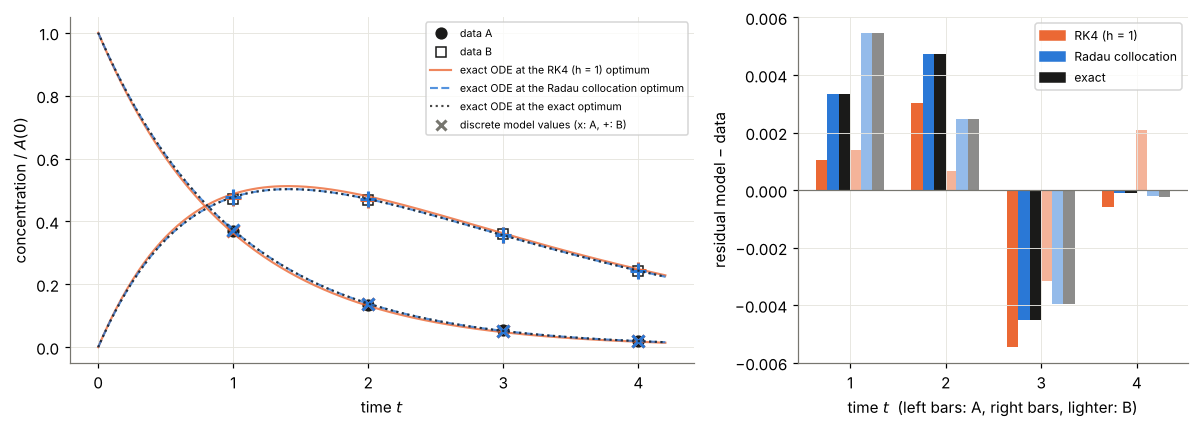

In [17]:
tt = np.linspace(0, 4.2, 200)
fig, axes = plt.subplots(1, 2, figsize=(11, 4), gridspec_kw=dict(width_ratios=[1.6, 1]))
ax = axes[0]
ax.plot(T_OBS, Y_A, "o", color=INK, ms=7, label="data A")
ax.plot(T_OBS, Y_B, "s", color=INK, ms=7, mfc="white", label="data B")
for i, (name, (states, col)) in enumerate(models.items()):
    k = fits[name]
    A, B = exact(k[0], k[1], tt)
    ax.plot(tt, A, color=col, lw=1.4, alpha=0.8, ls=("-", "--", ":")[i])
    ax.plot(tt, B, color=col, lw=1.4, alpha=0.8, ls=("-", "--", ":")[i], label=f"exact ODE at the {name} optimum")
    if name != "exact":
        Ad, Bd = states(k)
        ax.plot(T_OBS, Ad, "x", color=col, ms=8, mew=2)
        ax.plot(T_OBS, Bd, "+", color=col, ms=10, mew=2)
ax.plot([], [], "x", color=MUTED, mew=2, label="discrete model values (x: A, +: B)")
ax.set_xlabel("time $t$")
ax.set_ylabel("concentration / $A(0)$")
ax.legend(fontsize=7)
ax = axes[1]
w = 0.12
for i, (name, (states, col)) in enumerate(models.items()):
    res = states(fits[name]) - np.array([Y_A, Y_B])
    ax.bar(T_OBS - 0.3 + i * w, res[0], w, color=col, label=name if i == 0 else None)
    ax.bar(T_OBS + 0.05 + i * w, res[1], w, color=col, alpha=0.5)
ax.axhline(0, color=MUTED, lw=0.8)
ax.set_xticks(T_OBS)
ax.set_xlabel("time $t$  (left bars: A, right bars, lighter: B)")
ax.set_ylabel("residual model − data")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for _, c in models.values()], labels=list(models), fontsize=8)
plt.tight_layout()
plt.show()

Two things to read off. On the left, the discrete RK4 values (orange crosses)
lie on the data, while the exact solution at the same parameters (solid orange
curve) does not quite pass through them: the fit absorbs the discretization
error into $k$. On the right, the residuals of all three models are of the
size of the noise ($\sigma = 0.01$), and the exact model and collocation
leave nearly the same residuals.

The estimates differ in the second decimal, which is the discretization difference (RK4 with $h=1$ versus Radau collocation), not a solver disagreement.
The `pyomo.dae` model is declared in fewer lines than the explicit one; the transformation generates the many variables and constraints.

## Does `lax.scan` work for the loop?

Python loops are unrolled in the trace, which is why compile time grows with the number of steps. A `lax.scan` keeps the
jaxpr small. Does it make the solve cheaper?

In [18]:
import jax


def sse_scan(k):
    def body(carry, y):
        A, B = rk4_step(carry[0], carry[1], k[0], k[1])
        return (A, B), (A - y[0]) ** 2 + (B - y[1]) ** 2

    _, errs = jax.lax.scan(body, (1.0, 0.0), np.c_[Y_A, Y_B])
    return errs.sum()


try:
    print(solve_jax(sse_scan, [0.1, 0.1], [3.0, 3.0], tlim=30, **JAX_OPTS))
except Exception as e:  # noqa: BLE001
    print(f"{type(e).__name__}: {e}")

{'solver': 'jaxglobal', 'obj': inf, 'bound': -inf, 'time': 30.000680798999383, 'status': 'time_limit', 'x': array([1.55, 1.55]), 'nodes': 0}


It does not. Since PR #81 jaxglobal's relaxation interpreter unrolls a
`scan` with a fixed length, exactly as the trace unrolls the Python loop
(before #81 it evaluated the body once, and this cell failed with a shape
error). The relaxation is therefore the same unrolled graph as for the
Python-loop model, with the same compile cost: in the 30 s given here the
first compilation does not finish (no nodes, no point; the line above). The
Python-loop solve earlier in this notebook reused kernels already compiled
and cached on disk. `jaxglobal.export` also unrolls `scan` when it translates
a model for SCIP. The exported
problem is the reduced-space model (two variables, the objective one long
expression of degree 32 in $k$), not the full-space model of the Pyomo
section, and that matters to SCIP: give it 10 s and compare its dual bound
with the full-space solve in the table above.


In [19]:
from jaxglobal import export

t0 = time.perf_counter()
ms = export.to_scip(sse_scan, [0.1, 0.1], [3.0, 3.0])
ms.hideOutput()
ms.setParam("limits/gap", 1e-4)
ms.setParam("limits/absgap", 1e-6)
ms.setParam("limits/time", 10)
ms.optimize()
x_scan = export.solution(ms)
print(f"SCIP on the exported lax.scan model: status {ms.getStatus()}, obj {ms.getObjVal():.6e}, bound {ms.getDualbound():.6e}, "
      f"{ms.getNNodes()} nodes, {time.perf_counter() - t0:.1f} s (export included)")
print(f"k1, k2 = {x_scan[0]:.4f}, {x_scan[1]:.4f};  sse evaluated in numpy at that point: {float(sse(x_scan)):.6e}")

SCIP on the exported lax.scan model: status timelimit, obj 5.715675e-05, bound -3.974495e+09, 202 nodes, 10.1 s (export included)
k1, k2 = 1.0146, 0.4760;  sse evaluated in numpy at that point: 5.716690e-05


SCIP finds the right point quickly (its local heuristics work on any
formulation), but its relaxation of the composed polynomial is far too weak
to bound it in this time, whereas the full-space model, with each step's
states as bounded variables in $[0, 1]$, lets SCIP relax one step at a time.
The objective SCIP reports can sit slightly below the true SSE at its point,
because of the feasibility tolerance on the auxiliary variables the export
introduces; that is why the last line re-evaluates `sse`. jaxglobal relaxes the same
reduced-space composition, but its McCormick relaxations, which carry an interval
and a convex/concave pair for every intermediate, are tight enough to close
the gap here (with many nodes, as seen above).

## Time, model size and code

Wall-clock time of every solve above (log scale), the size of each Pyomo model
against the two variables jaxglobal branches on, and lines of model code as
counted by `nbutil.loc` (the shared `rk4_step` counted on both sides).

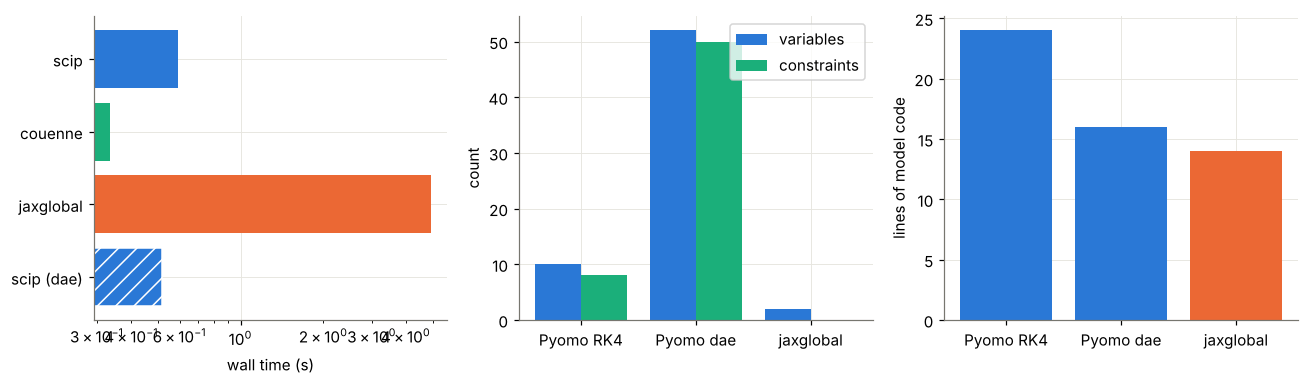

jaxglobal time / fastest Pyomo time on the RK4 model: 15x


In [20]:
all_rows = [r for r in rows + rows_dae if np.isfinite(r["obj"])]
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
for ax in axes:
    ax.set_axisbelow(True)
ax = axes[0]
names = [r["solver"] for r in all_rows]
ax.barh(names, [r["time"] for r in all_rows], color=[COLOR[n.split()[0]] for n in names])
for bar, n in zip(ax.patches, names):
    if "dae" in n:
        bar.set_hatch("//")
        bar.set_edgecolor("white")
ax.set_xscale("log")
ax.set_xlabel("wall time (s)")
ax.invert_yaxis()
ax = axes[1]
labels = ["Pyomo RK4", "Pyomo dae", "jaxglobal"]
nv, nc = [size[0], size_dae[0], 2], [size[1], size_dae[1], 0]
x = np.arange(3)
ax.bar(x - 0.2, nv, 0.4, color=BLUE, label="variables")
ax.bar(x + 0.2, nc, 0.4, color=AQUA, label="constraints")
ax.set_xticks(x, labels)
ax.set_ylabel("count")
ax.legend()
ax = axes[2]
ax.bar(labels, [lp, loc(dae_pyomo), lj], color=[BLUE, BLUE, ORANGE])
ax.set_ylabel("lines of model code")
plt.tight_layout()
plt.show()
print(f"jaxglobal time / fastest Pyomo time on the RK4 model: {rows[-1]['time'] / min(r['time'] for r in pyomo_rows):.0f}x")

## What was hard

**In Pyomo**

* Writing the model is not hard, and `pyomo.dae` is the better abstraction for dynamic models than hand-written equations: the discretization is a one-line choice, and it scales to PDEs.
* The size is the issue. Every state at every time point is a decision variable and every step is a constraint (10 variables here, 52 with collocation, for 2 parameters).
  For an experiment with 100 time points and 10 species that is thousands of variables, each tied by a nonconvex equation; a global solver must branch on them.
  Here the Pyomo solvers all finish quickly (table above) because the problem is tiny.
* Everything must be a variable or an expression of variables. If the rate law needs an `if`, a table lookup or a call to an existing integrator (e.g. `scipy.integrate`), it cannot be used.

**In jaxglobal**

* The model is the program: 2 variables, the integrator is a loop, and changing the integrator (RK4 for RK2, a different step) means editing one function.
* The bound is computed through the unrolled computation graph by McCormick relaxations, which suffer from the dependency problem: bounds on the states of step *n* are computed from bounds on step *n-1*, and the overestimation compounds. This is why the node count is large for a 2-parameter problem (compare with the Pyomo solvers, which branch on a few variables with strong relaxations of each bilinear term).
* **Compile time grows quickly with the number of steps.** The loop is unrolled, and with the default bound-tightening options (OBBT, FBBT, univariate and alphaBB relaxations) the first compilation did not finish in several minutes for three RK4 steps on this machine. With those options off, four steps solve in tens of seconds, most of it compilation; the kernels are cached on disk (`jaxglobal/kcache.py`), and on a cold cache and a busy machine the compilation alone can use up the 60 s limit. `lax.scan` over the steps is not supported by `minimize` (see the cell above; `jaxglobal.export` does unroll it), so long time horizons are not practical today. That is the main limitation shown by this notebook.
* Timings above are wall-clock on a loaded machine; the Pyomo solvers are faster in this case by the factor printed above.

**Verdict.** For a problem this small, Pyomo with a mature global solver is the better tool today. The jaxglobal advantage in this notebook is in what the model looks like and how little must be restated
(and in the fact that the same code can be differentiated or run in a simulator without changes), not in solve time.
The landscape shows why a global solver is worth having even here: one random start in several sends a local solver to the spurious RK4 minimum.